# 04 · Feature engineering, feature sets and leakage checks
**Feature sets.** **A** raw predictors (wind direction one-hot, reference level N); **B** the *k* most correlated features, with the ranking recomputed **inside every training fold**
(k ∈ {5, 10, 15, 20}; Pearson or Spearman); **C** engineered features in five motivated groups (temporal, PM2.5 history, shifted rolling statistics, environmental differences, interactions).
**Missing values.** The target is never filled; the current PM2.5 must be observed; PM2.5 *history* features use a causal last-observation-carried-forward over gaps of at most 3 hours;
every other variable is imputed inside each training fold (`SimpleImputer`).
**Code.** `src/features.py` (`build_candidate_features`, `build_specs`, `check_no_data_leakage`), `src/preprocessing.py` (leakage-safe transformers and `build_pipeline`).

In [1]:
import io, json, re, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
from PIL import Image as PILImage
from IPython.display import Image, Markdown, display
from src import config as C

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 90)

def table(stem, **kw):
    """results/tables/<stem>.csv (written by run_all.py)."""
    return pd.read_csv(C.TABLES / f"{stem}.csv", **kw)

def caption(stem):
    txt = (C.FIGURES / "figure_captions.md").read_text()
    m = re.search(rf"\*\*{re.escape(stem)}\*\* - (.*?)(?:\n\n|\Z)", txt, re.S)
    return m.group(1).strip() if m else ""

def fig(stem, width=1500):
    """Show results/figures/<stem>.png (down-scaled to keep the notebook small) with the caption computed from the data."""
    im = PILImage.open(C.FIGURES / f"{stem}.png")
    if im.width > width:
        im = im.resize((width, round(im.height * width / im.width)), PILImage.LANCZOS)
    buf = io.BytesIO(); im.save(buf, format="PNG", optimize=True)
    display(Image(data=buf.getvalue())); display(Markdown(f"*{caption(stem)}*"))

def log_grep(pattern, maxlen=420):
    """Print the lines of results/logs/run_all.log that match a regular expression."""
    for line in (C.LOGS / "run_all.log").read_text().splitlines():
        if re.search(pattern, line):
            print(line[:maxlen])

## 1. Feature groups, rationale and the hypothesis each group tests (Table 2)

In [2]:
display(table("table_2_feature_groups_and_rationale"))
display(table("table_S04_derived_feature_candidates").round(3))

,group,n_features,features,rationale,tests
0,Current PM2.5,1,PM25_t,The latest observed PM2.5 is the natural anchor of a next-hour forecast (lag-1 autocor...,H1
1,Temporal,7,"hour_sin, hour_cos, dow_sin, dow_cos, month_sin, month_cos, is_weekend","PM2.5 shows a daily cycle (night maximum, afternoon minimum), a seasonal cycle (Oct-De...",H3
2,PM2.5 lags,7,"PM25_lag_1, PM25_lag_3, PM25_lag_6, PM25_lag_12, PM25_lag_24, PM25_lag_48, PM25_lag_168","Concentrations persist over hours (1-6 h), days (24 / 48 h) and weeks (168 h); individ...","H1, H4"
3,PM2.5 rolling statistics,6,"PM25_roll_mean_3, PM25_roll_mean_6, PM25_roll_mean_12, PM25_roll_mean_24, PM25_roll_st...",Means and standard deviations of the shifted series (window ends at t-1) summarise rec...,H4
4,Pollutants (raw),5,"PM10, SO2, NO2, CO, O3",Co-pollutants share sources and meteorology with PM2.5 (PM10 and CO are strongly corre...,H2
5,Meteorology (raw),5,"TEMP, PRES, RAIN, WSPM, wd (15 one-hot dummies, reference N)",Wind speed/direction ventilate the air; precipitation scavenges particles; pressure an...,H2
6,Derived differences,3,"TEMP_minus_DEWP, DEWP_chg_3h, PM25_PM10_ratio",Physically motivated quantities that passed the training-only EDA rule (|Spearman| >= ...,H2
7,Interactions (centred products),6,"TEMP_x_DEWP, TEMP_x_PM10, WSPM_x_PM10, WSPM_x_PM25, TEMP_x_hour_sin, DEWP_x_hour_sin","Context-dependent effects: ventilation x load, temperature x moisture, seasonal compos...",H2 (context)


,candidate,rationale,rho_with_target,rho_with_next_hour_change,max_abs_rho,kept
0,TEMP_minus_DEWP,"dew-point depression: a humidity proxy (small = moist air, hygroscopic growth / second...",-0.471,-0.032,0.471,True
1,PRES_chg_3h,3-hour pressure tendency: falling pressure marks stagnation / approaching fronts,-0.052,-0.008,0.052,False
2,TEMP_chg_3h,3-hour temperature tendency (temperature-related difference),-0.007,-0.070,0.070,False
3,DEWP_chg_3h,3-hour dew-point tendency: rising moisture accompanies accumulation episodes,0.146,0.239,0.239,True
4,PM25_PM10_ratio,fine-particle fraction PM2.5(t)/PM10(t): secondary/combustion aerosol vs coarse dust,0.322,-0.130,0.322,True


## 2. Build the training matrices and run `check_no_data_leakage()` (live)
The checks perturb the future and verify that no feature changes (rolling windows and lags use only the past), that the target never enters the inputs, that the test vault is untouched,
and that imputer medians, scaler statistics and the top-k ranking depend on the **training fold only**.

In [3]:
from src import data as D, features as F, models as M
raw = D.load_raw()
df, _ = D.build_datetime(raw)
df, _ = D.drop_identifier_columns(df)
df = D.make_target(df)                                     # target(t) = PM2.5(t+1); the last hour is removed; asserted inside
train, vault, info = D.chronological_split(df)             # earliest 80 % = train, latest 20 % = locked vault
del df                                                     # only the training rows stay in memory

feats = F.build_candidate_features(train)                  # features at hour t from information up to t only
elig = F.eligibility(train, feats)                         # the same usability rule for every model
X = feats.loc[elig].reset_index(drop=True)
y = train.loc[elig, C.TARGET].reset_index(drop=True)
dtab = F.derived_candidate_table(X, y)
specs = F.build_specs(dtab.loc[dtab["kept"], "candidate"].tolist())
print(f"{len(X):,} usable training rows of {len(train):,} | candidate columns: {X.shape[1]}")
chk = F.check_no_data_leakage(train_frame=train, X_train=X, y_train=y, spec=specs["C"], cv=M.make_cv(), vault=vault, verbose=False)
display(chk)
assert chk["passed"].all(), "a leakage check failed"
print(f"all {len(chk)} checks passed")

26,000 usable training rows of 28,050 | candidate columns: 37


,check,passed
0,[synthetic] target = PM2.5(t+1); PM25_t = PM2.5(t); target not among features,True
1,"[synthetic] lag_k = PM2.5(t-k); rolling windows = PM2.5(t-1..t-w) (brute-force match, ...",True
2,[synthetic] perturbing PM2.5(t>t0) and the label leaves all features of rows <= t0 unc...,True
3,[synthetic] perturbing future meteorology / pollutants leaves rows <= t0 unchanged,True
4,[synthetic] features of the first half are identical whether or not the second half ex...,True
5,[synthetic] calendar and meteorological features do not use PM2.5,True
6,[real training rows] target = PM2.5(t+1); PM25_t = PM2.5(t); target not among features,True
7,[real training rows] lag_k = PM2.5(t-k); rolling windows = PM2.5(t-1..t-w) (brute-forc...,True
8,[real training rows] perturbing PM2.5(t>t0) and the label leaves all features of rows ...,True
9,[real training rows] perturbing future meteorology / pollutants leaves rows <= t0 unch...,True


all 14 checks passed


## 3. The three feature sets as used by the experiment

In [4]:
fl = json.loads((C.MODELS / "feature_lists.json").read_text())
for k, v in fl.items():
    print(f"{k:22s} ({len(v):2d})", v)

set_A_numeric          (11) ['PM25_t', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM']
set_A_categorical      ( 1) ['wd']
set_C_numeric          (33) ['PM25_t', 'PM25_lag_1', 'PM25_lag_3', 'PM25_lag_6', 'PM25_lag_12', 'PM25_lag_24', 'PM25_lag_48', 'PM25_lag_168', 'PM25_roll_mean_3', 'PM25_roll_mean_6', 'PM25_roll_mean_12', 'PM25_roll_mean_24', 'PM25_roll_std_6', 'PM25_roll_std_24', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'month_sin', 'month_cos', 'is_weekend', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'RAIN', 'WSPM', 'TEMP_minus_DEWP', 'DEWP_chg_3h', 'PM25_PM10_ratio']
set_C_pairs            ( 6) [['TEMP', 'DEWP', 'TEMP_x_DEWP'], ['TEMP', 'PM10', 'TEMP_x_PM10'], ['WSPM', 'PM10', 'WSPM_x_PM10'], ['WSPM', 'PM25_t', 'WSPM_x_PM25'], ['TEMP', 'hour_sin', 'TEMP_x_hour_sin'], ['DEWP', 'hour_sin', 'DEWP_x_hour_sin']]
set_C_design_columns   (54) ['PM25_t', 'PM25_lag_1', 'PM25_lag_3', 'PM25_lag_6', 'PM25_lag_12', 'PM25_lag_24', 'PM25_lag_48', 'PM25_lag_168

## 4. Missing-value policy, redundancy of the engineered design and the shared CV folds

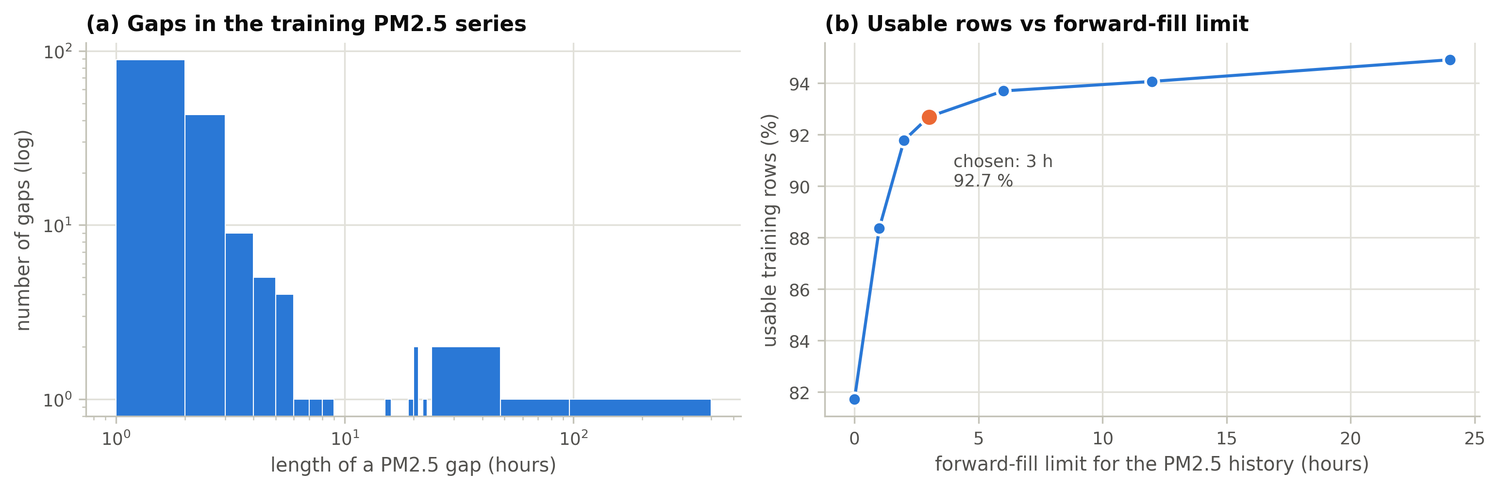

*Missing-value policy (training rows). (a) The PM2.5 series has 162 gaps; 87 % last at most 3 hours, the longest lasts 343 hours. (b) Causally forward-filling the PM2.5 history over gaps of up to 3 hours keeps 92.7 % of the training hours (no filling: 81.7 %); a 12-hour limit would add only 1.4 points and a 24-hour limit 2.2. The target is never filled; rows with unusable history are excluded identically for every model.*

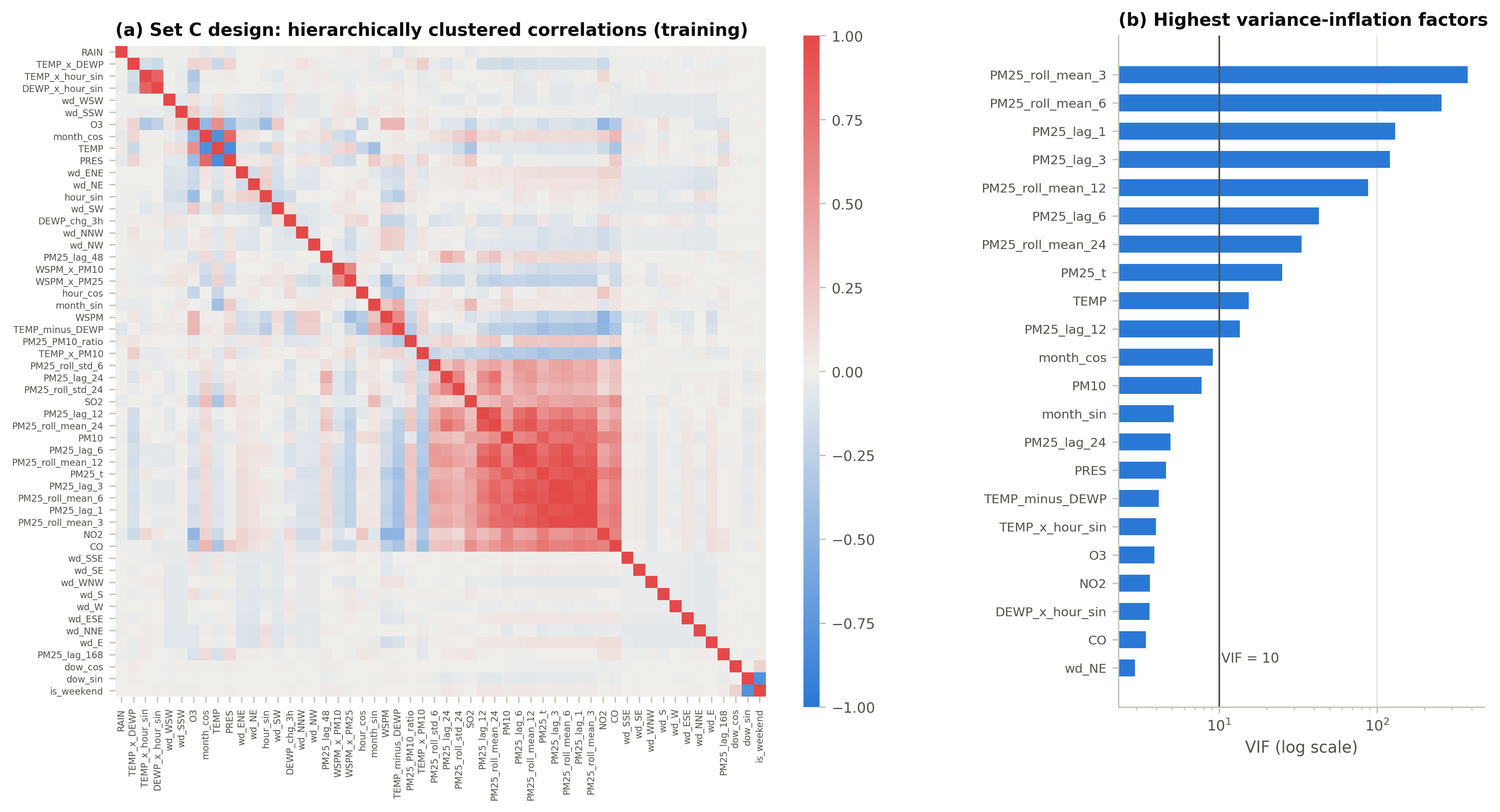

*Redundancy of the Set C training design (54 columns). (a) Pearson correlation matrix ordered by hierarchical clustering: the PM2.5 history (current value, lags, rolling means) forms one tightly correlated block that is also related to PM10, NO2 and CO. (b) The 22 columns with the highest variance-inflation factor (log axis): 10 columns exceed VIF = 10 (maximum 377 for PM25_roll_mean_3); the 10 largest are PM25_roll_mean_3, PM25_roll_mean_6, PM25_lag_1, PM25_lag_3, PM25_roll_mean_12, PM25_lag_6, PM25_roll_mean_24, PM25_t, TEMP, PM25_lag_12. Such collinearity makes individual history coefficients unstable and motivates penalised regression.*

,fold,train_rows,train_to,val_rows,val_from,val_to
0,1,4335,2013-09-05,4333,2013-09-05,2014-03-09
1,2,8668,2014-03-09,4333,2014-03-09,2014-09-14
2,3,13001,2014-09-14,4333,2014-09-14,2015-04-15
3,4,17334,2015-04-15,4333,2015-04-15,2015-10-31
4,5,21667,2015-10-31,4333,2015-10-31,2016-05-12


,check,passed
0,[synthetic] target = PM2.5(t+1); PM25_t = PM2.5(t); target not among features,True
1,"[synthetic] lag_k = PM2.5(t-k); rolling windows = PM2.5(t-1..t-w) (brute-force match, ...",True
2,[synthetic] perturbing PM2.5(t>t0) and the label leaves all features of rows <= t0 unc...,True
3,[synthetic] perturbing future meteorology / pollutants leaves rows <= t0 unchanged,True
4,[synthetic] features of the first half are identical whether or not the second half ex...,True
5,[synthetic] calendar and meteorological features do not use PM2.5,True
6,[real training rows] target = PM2.5(t+1); PM25_t = PM2.5(t); target not among features,True
7,[real training rows] lag_k = PM2.5(t-k); rolling windows = PM2.5(t-1..t-w) (brute-forc...,True
8,[real training rows] perturbing PM2.5(t>t0) and the label leaves all features of rows ...,True
9,[real training rows] perturbing future meteorology / pollutants leaves rows <= t0 unch...,True


In [5]:
fig("figure_S04_missing_values_policy")
fig("figure_S05_feature_redundancy")
display(table("table_S05_cv_folds"))
display(table("table_S06_leakage_checks"))